# Graph Attention Networks: does learning which neighbours matter actually help?

**CS545 Final Project - Hansi Yasodara (individual)**  ·  code: <https://github.com/YashDolorase/cs545-gat>

Graph neural networks (GNNs) classify a node by mixing its own features with its neighbours'. The question is
**how much weight each neighbour should get**:

| Model | Weight of neighbour $j$ when updating node $i$ | Learned? |
|---|---|---|
| **GCN** (Kipf & Welling, 2017) | $\frac{1}{\sqrt{(d_i+1)(d_j+1)}}$ (set by node degrees) | no |
| **GraphSAGE**-mean (Hamilton et al., 2017) | $\frac{1}{d_i}$ (plain average, plus a separate self weight) | no |
| **GAT** (Veličković et al., 2018) | $\alpha_{ij}$ = softmax of a learned score of $(h_i, h_j)$ | **yes** |

GAT brings the **attention** idea from the course (transformers) to graphs. Because the weights $\alpha_{ij}$ can be
read off, we can check what GAT has learned, not only how accurate it is.

**Key term: homophily.** Homophily ("love of the same") describes how often connected nodes belong to the same class.
In a citation graph, papers mostly cite papers on the same topic. Homophily is high there, so a node's neighbours are good
evidence for its own label. In a **low-homophily** graph most neighbours have a different label, so copying from them
misleads. We measure it as **edge homophily** (Section 1).

**Research questions** (from the proposal)
1. **Accuracy:** Does GAT beat GCN and GraphSAGE on Cora and CiteSeer by more than the variation across random seeds?
2. **Interpretation:** Are the learned attention weights close to uniform, or concentrated on neighbours of the same class?
3. **Robustness:** When random (mostly cross-class) edges are added, does GAT degrade more slowly and give those edges less attention?

**Roadmap**

| Section | Contents |
|---|---|
| 1. Data | Cora and CiteSeer citation graphs, edge homophily |
| 2. From fixed to learned weights | GCN, mean and GAT weights on a toy graph; static vs dynamic attention |
| 3. GAT layer from scratch | Implementation, verified against PyG's `GATConv` |
| 4. Models and training | Hyperparameters and training protocol |
| 5. E1: Benchmark | Accuracy of MLP, GCN, GraphSAGE and GAT over 10 seeds |
| 6. E2: Attention | Is the learned attention uniform or class-selective? |
| 7. E3: Noisy neighbours | Accuracy and attention with random edges added |
| 8. Stretch | GATv2 and low-homophily graphs (Texas, Chameleon) |
| 9. Conclusions | Answers to the research questions, limitations |
| 10. Contributions | Use of AI, resources, references |

### Summary of findings
* **E1:** GAT ≈ GCN. On Cora 82.3 ± 0.7 vs 82.1 ± 0.5 (paired over 10 seeds, $p=0.41$); on CiteSeer 71.5 ± 0.9 vs 71.0 ± 0.4 ($p=0.21$).
  Both clearly beat GraphSAGE (by ~1 point, $p<0.01$) and the graph-free MLP (by 14–23 points).
* **E2:** The trained GAT's attention is **almost exactly uniform**. Its entropy is 99.9 % of the uniform value, and the share
  of attention on same-class neighbours equals the share of same-class neighbours (0.816 vs 0.816 on Cora). In practice GAT
  behaves like a mean aggregator.
* **E3:** With random edges added, GAT degrades **no more slowly** than GCN. It gives injected edges only ~2 % less attention
  than real ones. GraphSAGE, which keeps a separate weight for a node's own features, is the most robust.
* **Stretch:** GATv2's dynamic attention (Section 2.3) does not change this. It matches GAT on all four graphs, and its attention is
  just as class-blind, even on the low-homophily graphs Texas and Chameleon, where GraphSAGE (separate self-weight) is
  clearly best and on Texas even the MLP beats every averaging model.

## 0. Setup
Works locally and on Google Colab. Heavy experiments live in `scripts/run_experiments.py`; this notebook reads their cached results from `results/` (set `RUN_EXPERIMENTS = True` to recompute, ~30 min on a T4 GPU).

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("src"):
    !git clone -q https://github.com/YashDolorase/cs545-gat.git /content/project
    os.chdir("/content/project")
    !pip -q install torch_geometric

import warnings; warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silences a harmless joblib warning on Windows
import inspect
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, networkx as nx
from scipy import stats
from IPython.display import display, Markdown, Code

sys.path.insert(0, os.getcwd())
from src.data import load_dataset, select_split, describe, edge_homophily
from src.gat_layer import GATLayer, check_against_pyg
from src.models import CONFIGS, build_model, count_params
from src.train import train_model, evaluate, get_device
from src.attention import get_attention, node_attention_stats, normalized_edge_attention

RUN_EXPERIMENTS = False          # True: re-run E1/E3 (+ stretch in Section 8) instead of loading results/*.csv
DATA, RES = "data", "results"
if RUN_EXPERIMENTS:
    !python scripts/run_experiments.py --exp e1
    !python scripts/run_experiments.py --exp e3

# One fixed colour per model (colour follows the model in every figure)
COL = {"GAT": "#2a78d6", "GCN": "#eb6834", "SAGE": "#1baf7a", "GATv2": "#e87ba4", "MLP": "#8a8985"}
SAME, OTHER = "#2a78d6", "#eb6834"   # same-class vs different-class neighbour
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#8a8985", "font.size": 10, "legend.frameon": False, "lines.linewidth": 2})
torch.manual_seed(0); np.random.seed(0)
print("torch", torch.__version__, "| device:", get_device())

torch 1.13.1+cpu | device: cpu


## 1. Data: citation graphs
Nodes are papers, edges are citations (treated as undirected), and features are bag-of-words vectors (row-normalised).
The task is to predict each paper's topic from only **140 (Cora) / 120 (CiteSeer) labelled nodes**, using the standard
public split from the GCN and GAT papers.

**Edge homophily** is the fraction of edges that join two nodes of the same class. It ranges from 0 to 1: at 1 every
edge links two papers on the same topic, and at 0 none does. For example, Cora's 0.81 means that 81 of every 100 citations
link two papers on the same topic. When it is high, simply averaging
neighbours already pulls nodes towards the right class. This number is the baseline for every attention statistic in Section 6:
if GAT spread its attention uniformly, about this share of it would land on same-class neighbours anyway.

In [2]:
datasets = {name: load_dataset(name, DATA)[1] for name in ["Cora", "CiteSeer"]}
display(pd.DataFrame([describe(n, d) for n, d in datasets.items()]).set_index("dataset"))

,nodes,edges (undirected),features,classes,train/val/test,mean degree,isolated nodes,edge homophily
dataset,,,,,,,,
Cora,2708,5278,1433,7,140/500/1000,3.90,0,0.810
CiteSeer,3327,4552,3703,6,120/500/1000,2.74,48,0.736


## 2. From fixed weights to learned weights

### 2.1 Message passing
Every model here is a 2-layer **message-passing** network. One layer updates each node from its neighbourhood $\mathcal N(i)$:
$$h_i' = \sigma\Big(\sum_{j\in\mathcal N(i)\cup\{i\}} c_{ij}\, W h_j\Big)$$
The only thing that changes between models is the coefficient $c_{ij}$.

### 2.2 GAT's attention
GAT computes $c_{ij}=\alpha_{ij}$ from the two nodes' features:
$$e_{ij} = \mathrm{LeakyReLU}\big(\mathbf a^\top [\,W h_i \,\Vert\, W h_j\,]\big), \qquad
\alpha_{ij} = \frac{\exp(e_{ij})}{\sum_{k\in\mathcal N(i)\cup\{i\}} \exp(e_{ik})}$$
* The softmax runs **over each neighbourhood**, so the weights are positive and sum to 1, like attention over tokens in a
  transformer. The difference is that a node only attends to its graph neighbours, not to every node.
* **Multi-head:** $K$ independent copies (here $K=8$, 8 units each) are concatenated in the hidden layer and averaged
  in the output layer. This stabilises training, much like multi-head self-attention.
* If every $e_{ij}$ in a neighbourhood is equal, $\alpha_{ij}=1/(d_i+1)$ and GAT **reduces to mean aggregation**.
  Section 6 checks how far the trained model is from this.

Below we compare the three weightings on a toy graph with two classes (blue = A, orange = B). We hand-set a GAT
attention vector that likes class-A neighbours.

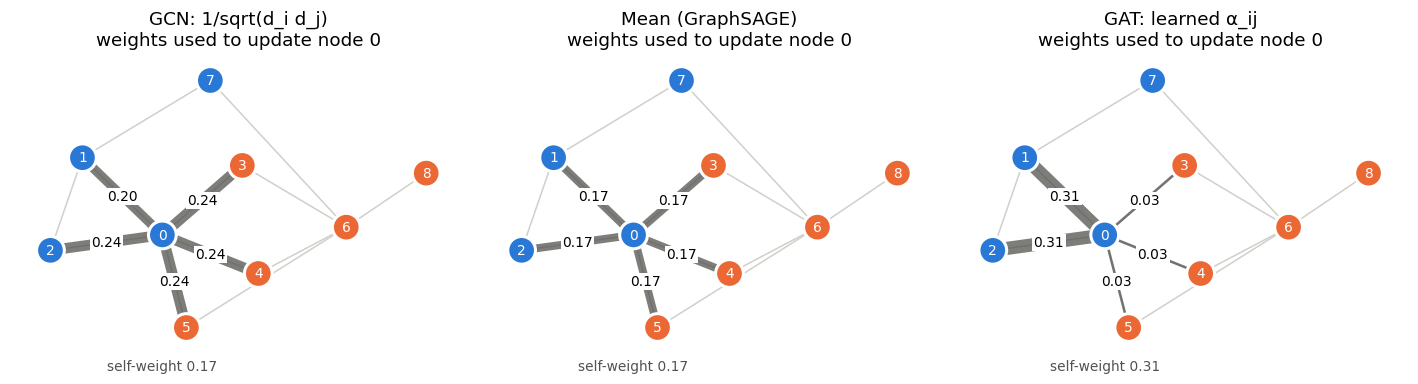

In [3]:
# Toy graph: node 0 (class A) is connected to 2 class-A and 3 class-B nodes; node 6 is a class-B hub.
edges = [(0,1),(0,2),(0,3),(0,4),(0,5),(1,2),(3,6),(4,6),(5,6),(6,7),(6,8),(1,7)]
labels = np.array([0,0,0,1,1,1,1,0,1])           # 0 = A, 1 = B
N = len(labels)
ei = torch.tensor(edges).T; ei = torch.cat([ei, ei.flip(0)], 1)
x = F.one_hot(torch.tensor(labels, dtype=torch.long), 2).float()   # features = class indicator (idealised)

deg = torch.bincount(ei[1], minlength=N).float() + 1      # + self-loop
def gcn_w(i, j): return (1 / torch.sqrt(deg[i] * deg[j])).item()
def mean_w(i, j): return (1 / deg[i]).item()

gat = GATLayer(2, 2, heads=1, self_loops=True).eval()
with torch.no_grad():                            # W = identity, attention vector favours class-A neighbours
    gat.W.weight.copy_(torch.eye(2)); gat.att_src.copy_(torch.tensor([[[2.0, -2.0]]])); gat.att_dst.zero_()
    _, (gei, galpha) = gat(x, ei, return_attention_weights=True)
def gat_w(i, j): return galpha[((gei[0] == j) & (gei[1] == i)).nonzero()[0, 0], 0].item()

pos = {0:(0,0),1:(-1,1),2:(-1.4,-.2),3:(1,.9),4:(1.2,-.5),5:(.3,-1.2),6:(2.3,.1),7:(.6,2),8:(3.3,.8)}
G = nx.Graph(edges)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, w) in zip(axes, [("GCN: 1/sqrt(d_i d_j)", gcn_w), ("Mean (GraphSAGE)", mean_w), ("GAT: learned α_ij", gat_w)]):
    ax.set_title(f"{title}\nweights used to update node 0"); ax.axis("off")
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#d0cfca", width=1)
    nbrs = [1,2,3,4,5]
    for j in nbrs:
        wij = w(0, j)
        nx.draw_networkx_edges(G, pos, edgelist=[(0, j)], ax=ax, width=1 + 25 * wij, edge_color="#52514e", alpha=.75)
        mx, my = (pos[0][0]+pos[j][0])/2, (pos[0][1]+pos[j][1])/2
        ax.text(mx, my, f"{wij:.2f}", fontsize=9, ha="center", va="center", bbox=dict(fc="white", ec="none", pad=1))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[SAME if l == 0 else OTHER for l in labels], node_size=330,
                           edgecolors="white", linewidths=2)
    nx.draw_networkx_labels(G, pos, ax=ax, font_color="white", font_size=9)
    ax.text(0, -1.75, f"self-weight {w(0,0):.2f}", ha="center", fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

GCN and the mean give every neighbour of node 0 roughly the same weight. They differ only through degrees: neighbour 5 has
fewer links than 4, so GCN gives it slightly more. The hand-set GAT puts most of the weight on the two **same-class**
neighbours (1, 2). This is the promise of attention: it can ignore neighbours that are unhelpful.

### 2.3 A catch: GAT's attention is static
Write $\mathbf a=[\mathbf a_{dst}\Vert\mathbf a_{src}]$. Then $e_{ij}=\mathrm{LeakyReLU}(\mathbf a_{dst}^\top Wh_i+\mathbf a_{src}^\top Wh_j)$.
The first term is the same for every neighbour of $i$, and LeakyReLU is monotone. So **the ranking of neighbours is set by
$\mathbf a_{src}^\top Wh_j$ alone and is the same for every query node $i$** (Brody et al., 2022). If GAT likes class-A
neighbours, it likes them for class-B nodes too. It cannot learn "attend to nodes of my class" for both classes at once.

GATv2 moves the nonlinearity inside: $e_{ij}=\mathbf a^\top\mathrm{LeakyReLU}(W_{dst}h_i+W_{src}h_j)$. This makes the
ranking depend on $i$ ("dynamic attention"). The toy check below uses hand-set weights for both models.

In [4]:
# Same toy graph. Query: how much attention does each node put on SAME-class neighbours?
def same_class_share(alpha, e_idx):
    out = {}
    for i in [0, 6]:
        m = (e_idx[1] == i) & (e_idx[0] != i)
        a, j = alpha[m], e_idx[0][m]
        out[i] = (a[labels[j] == labels[i]].sum() / a.sum()).item()
    return out

# GAT (static): best possible single attention vector still favours class A for everyone
static = same_class_share(galpha[:, 0], gei)

# GATv2 (dynamic), set by hand: e_ij = a . LeakyReLU(3*(h_i + h_j - 1)), a = [1, 1]
#   same class -> LeakyReLU([3,-3]) = [3,-0.6] -> e = 2.4 ;  different class -> [0,0] -> e = 0
hi, hj = x[gei[1]], x[gei[0]]
e2 = (F.leaky_relu(3 * (hi + hj - 1), 0.2)).sum(-1)
from src.gat_layer import segment_softmax
alpha2 = segment_softmax(e2.unsqueeze(-1), gei[1], N)[:, 0]
dynamic = same_class_share(alpha2, gei)

uniform = {i: float(np.mean(labels[list(G.neighbors(i))] == labels[i])) for i in [0, 6]}
display(pd.DataFrame({"uniform (mean)": uniform, "GAT, a favours class A": static, "GATv2, hand-set": dynamic},
                     index=pd.Index([0, 6], name="query node")).rename(index={0: "node 0 (class A)", 6: "node 6 (class B)"}).round(2))

,uniform (mean),"GAT, a favours class A","GATv2, hand-set"
query node,,,
node 0 (class A),0.4,0.88,0.88
node 6 (class B),0.8,0.27,0.98


The static GAT helps node 0 (class A) but **hurts** node 6 (class B): it still favours class-A neighbours, so less of
node 6's attention lands on its own class than uniform weights would give. GATv2 can raise the same-class share for both.
Real features are not class indicators, and 8 heads give GAT more freedom than this toy. Even so, this limit is one
possible reason the trained GAT ends up close to uniform (Section 6).

## 3. The GAT layer from scratch
`src/gat_layer.py` implements the layer with plain PyTorch ops. The neighbourhood softmax is computed edge-wise with a
scatter-max for numerical stability, then a scatter-sum.

In [5]:
from src import gat_layer
display(Code(inspect.getsource(gat_layer.segment_softmax) + "\n" + inspect.getsource(GATLayer.forward), language="python"))

def segment_softmax(scores, index, num_nodes):
    """Softmax of `scores` [E, H] within groups of edges sharing the same target `index` [E]."""
    idx = index.unsqueeze(-1).expand_as(scores)
    # subtract per-group max for numerical stability
    group_max = torch.full((num_nodes, scores.size(1)), float("-inf"), device=scores.device, dtype=scores.dtype)
    group_max = group_max.scatter_reduce(0, idx, scores, reduce="amax", include_self=True)
    exp = (scores - group_max[index]).exp()
    denom = torch.zeros((num_nodes, scores.size(1)), device=scores.device, dtype=scores.dtype)
    denom = denom.index_add(0, index, exp)
    return exp / (denom[index] + 1e-16)

    def forward(self, x, edge_index, return_attention_weights=False):
        N, H, C = x.size(0), self.heads, self.out_dim
        if self.self_loops:
            edge_index = add_self_loops(edge_index, N)
        src, dst = edge_index  # message flows src (j) -> dst (i)

        h = self.W(x).view(N, H, C)                          # W h            [N, H, C]
        score_src = (h * self.att_src).sum(-1)               # a_src . W h_j  [N, H]
        score_dst = (h * self.att_dst).sum(-1)               # a_dst . W h_i  [N, H]
        e = F.leaky_relu(score_src[src] + score_dst[dst], self.negative_slope)  # [E, H]

        alpha = segment_softmax(e, dst, N)                   # normalise over each neighbourhood
        alpha_drop = F.dropout(alpha, p=self.dropout, training=self.training)

        out = torch.zeros(N, H, C, device=x.device, dtype=h.dtype)
        out = out.index_add(0, dst, h[src] * alpha_drop.unsqueeze(-1))
        out = out.reshape(N, H * C) if self.concat else out.mean(dim=1)
        if self.bias is not None:
            out = out + self.bias

        if return_attention_weights:
            return out, (edge_index, alpha)
        return out

**Check against PyTorch Geometric.** We copy our weights into PyG's `GATConv` and compare outputs and attention on Cora for both a hidden layer (8 heads, concatenated) and an output layer (1 head, averaged).

In [6]:
cora = datasets["Cora"]
rows = [dict(layer=name, **check_against_pyg(cora.x, cora.edge_index, cora.num_features, out, heads=h, concat=c))
        for name, out, h, c in [("hidden: 8 heads x 8, concat", 8, 8, True), ("output: 1 head x 7, mean", 7, 1, False)]]
display(pd.DataFrame(rows).set_index("layer"))

,output_max_abs_diff,attention_max_abs_diff,match
layer,,,
"hidden: 8 heads x 8, concat",0.0,0.0,True
"output: 1 head x 7, mean",0.0,0.0,True


## 4. Models and training protocol
All models have **two layers** and use the hyperparameters from their original papers. The **MLP** ignores the edges
completely, so it shows how much the graph itself adds.
* Full-batch Adam, cross-entropy on the labelled nodes, up to 1000 epochs.
* **Early stopping on validation accuracy** (patience 100, ties broken by validation loss); we report test accuracy of the best-validation weights.
* **10 seeds** (0–9) per model. Each seed is shared across models, so comparisons are **paired**.
* E1/E3 ran on a Colab T4 GPU; times are per training epoch on that GPU.
* **Reruns match closely, but not always to the last digit.** A seed fixes the initial weights, the dropout masks and the noisy
  graph, but some GPU operations (parallel scatter-sums over edges) add numbers in an unfixed order. An independent full
  rerun on a T4 reproduced 279 of the 280 E1/E3 runs exactly. In the stretch runs (the denser Chameleon graph, and PyG's
  `GATv2Conv`), 134 of 170 matched exactly and no model's mean moved by more than 0.5 points (on Texas one test node is
  2.7 points). No conclusion changed. Rerunning the runner notebooks can therefore give slightly different numbers from `results/`.

In [7]:
cfg = pd.DataFrame(CONFIGS).T
cfg["params (Cora)"] = [count_params(build_model(m, cora.num_features, 7)) for m in cfg.index]
display(cfg.fillna("").astype(str))

,hidden,dropout,lr,weight_decay,heads,params (Cora)
MLP,64.0,0.5,0.01,0.0005,,92231
GCN,16.0,0.5,0.01,0.0005,,23063
SAGE,64.0,0.5,0.01,0.0005,,184391
GAT,8.0,0.6,0.005,0.0005,8.0,92373
GATv2,8.0,0.6,0.005,0.0005,8.0,184604


## 5. E1: Benchmark (RQ1)

In [8]:
e1 = pd.read_csv(f"{RES}/e1_benchmark.csv")
MAIN = ["MLP", "GCN", "SAGE", "GAT"]
main = e1[e1.dataset.isin(["Cora", "CiteSeer"]) & e1.model.isin(MAIN)]
tab = main.groupby(["dataset", "model"]).agg(
    test_acc=("test_acc", lambda s: f"{100*s.mean():.1f} ± {100*s.std():.1f}"),
    params=("params", "first"), ms_per_epoch=("ms_per_epoch", "mean"), best_epoch=("best_epoch", "mean"), runs=("seed", "count"))
tab = tab.reindex(pd.MultiIndex.from_product([["Cora", "CiteSeer"], MAIN])).round(1)
display(tab)

test_acc  params  ms_per_epoch  best_epoch  runs
Cora     MLP   59.0 ± 0.9   92231           2.0        99.7    10
         GCN   82.1 ± 0.5   23063           3.5       267.7    10
         SAGE  81.3 ± 0.6  184391           3.9       112.1    10
         GAT   82.3 ± 0.7   92373           7.0       152.2    10
CiteSeer MLP   57.3 ± 1.1  237446           2.8       124.8    10
         GCN   71.0 ± 0.4   59366           4.1       218.7    10
         SAGE  70.2 ± 0.7  474822           6.8        84.1    10
         GAT   71.5 ± 0.9  237586           7.1        76.5    10

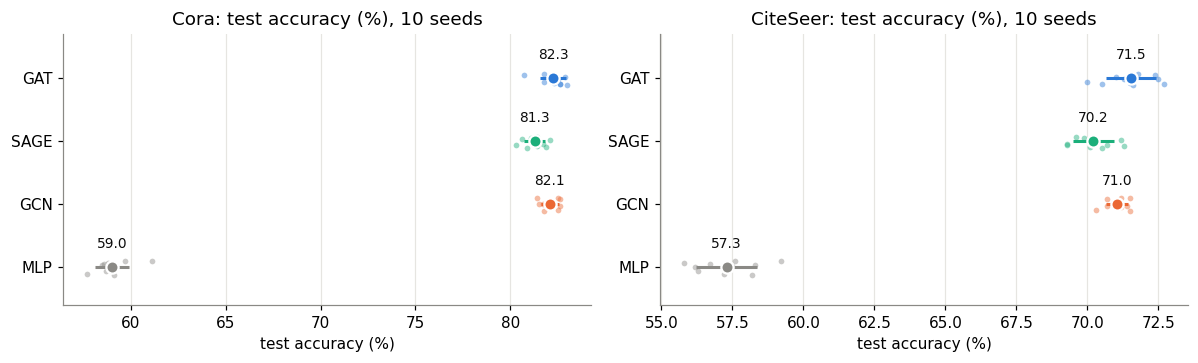

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, ds in zip(axes, ["Cora", "CiteSeer"]):
    d = main[main.dataset == ds]
    for k, m in enumerate(MAIN):
        acc = 100 * d[d.model == m].test_acc.values
        jitter = np.random.default_rng(k).uniform(-.12, .12, len(acc))
        ax.scatter(acc, k + jitter, s=14, color=COL[m], alpha=.45, linewidths=0)
        ax.errorbar(acc.mean(), k, xerr=acc.std(ddof=1), fmt="o", ms=8, color=COL[m], capsize=0, elinewidth=2,
                    markeredgecolor="white", markeredgewidth=1.5)
        ax.text(acc.mean(), k + .3, f"{acc.mean():.1f}", ha="center", fontsize=9, color="#0b0b0b")
    ax.set_yticks(range(len(MAIN)), MAIN); ax.set_ylim(-.6, len(MAIN) - .3)
    ax.set_title(f"{ds}: test accuracy (%), 10 seeds"); ax.set_xlabel("test accuracy (%)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Is the difference bigger than seed-to-seed noise?** Paired comparison over the 10 shared seeds (mean difference, paired t-test, and how many seeds GAT wins):

In [10]:
rows = []
for ds in ["Cora", "CiteSeer"]:
    p = main[main.dataset == ds].pivot(index="seed", columns="model", values="test_acc") * 100
    for b in ["GCN", "SAGE", "MLP"]:
        diff = p.GAT - p[b]
        rows.append({"dataset": ds, "comparison": f"GAT − {b}", "mean diff (pts)": diff.mean(), "std": diff.std(),
                     "paired t p-value": stats.ttest_rel(p.GAT, p[b]).pvalue, "GAT wins": f"{(diff > 0).sum()}/10"})
display(pd.DataFrame(rows).set_index(["dataset", "comparison"]).round(3))

mean diff (pts)    std  paired t p-value GAT wins
dataset  comparison                                                   
Cora     GAT − GCN              0.18  0.656             0.408     6/10
         GAT − SAGE             0.98  0.614             0.001    10/10
         GAT − MLP             23.26  1.005             0.000    10/10
CiteSeer GAT − GCN              0.49  1.136             0.206     7/10
         GAT − SAGE             1.32  1.013             0.003     9/10
         GAT − MLP             14.23  1.629             0.000    10/10

**Answer to RQ1: no, not against GCN.**
* GAT's lead over GCN (+0.2 pts on Cora, +0.5 on CiteSeer) is smaller than the seed-to-seed spread ($p=0.41$, $0.21$).
  We reproduce the GAT paper's Cora number almost exactly (82.3 vs 83.0). Our GCN, however, scores 82.1, higher than the
  81.5 reported for it. The original 1.5-point gap closes under one shared protocol. Shchur et al. (2018) observed the same
  sensitivity to evaluation setup.
* GAT does beat GraphSAGE-mean consistently (+1.0 / +1.3 pts, 10/10 and 9/10 seeds).
* Every graph model beats the MLP by 14–23 points, so the edges matter a lot. How neighbours are weighted matters much less.
* Cost: GAT has 4× GCN's parameters and is ~2× slower per epoch. It stops earlier, though, so total training time is similar.

## 6. E2: What does GAT attend to? (RQ2)
We load the GAT trained with seed 0 (saved by the E1 run) and read its attention $\alpha_{ij}$ for both layers.
Unless stated otherwise, values are averaged over heads. For each node $i$ with degree $d_i$:
* **attention entropy** $H_i=-\sum_j\alpha_{ij}\log\alpha_{ij}$, compared with the **uniform** value $\log(d_i+1)$.
* **same-class attention**: the share of neighbour attention (self excluded) on neighbours with $y_j=y_i$, compared with
  the share of neighbours that are same-class (what uniform weights give).
* **normalised attention** $\alpha_{ij}(d_i+1)$, which equals 1 for uniform attention.

In [11]:
def load_gat(ds, name="GAT"):
    data = datasets[ds]
    m = build_model(name, data.num_features, int(data.y.max()) + 1)
    m.load_state_dict(torch.load(f"{RES}/{name}_{ds}_seed0.pt", map_location="cpu")); m.eval()
    return m

def attention_summary(model, data, name):
    model.eval()
    with torch.no_grad():
        _, atts = model(data.x, data.edge_index, return_attention=True)
    out = []
    for L, (ei_, a) in enumerate(atts, 1):
        st = node_attention_stats(ei_, a.mean(1), data.y, data.num_nodes); s = st[st.degree >= 2]
        norm = normalized_edge_attention(ei_, a.mean(1), data.num_nodes)[ei_[0] != ei_[1]]
        out.append({"model": name, "layer": L, "entropy / uniform": (s.entropy / s.uniform_entropy).mean(),
                    "same-class attention": s.same_class_att.mean(), "same-class fraction (uniform)": s.same_class_frac.mean(),
                    "self attention": st.self_att.mean(), "uniform self 1/(d+1)": (1 / (st.degree + 1)).mean(),
                    "norm. att. 5–95% range": f"{np.quantile(norm, .05):.2f}–{np.quantile(norm, .95):.2f}"})
    return out

gats = {ds: load_gat(ds) for ds in datasets}
rows = []
for dsn, m in gats.items():
    print(f"{dsn}: reloaded GAT test acc = {evaluate(m, datasets[dsn])['test_acc']:.3f}")
    rows += [{"dataset": dsn, **r} for r in attention_summary(m, datasets[dsn], "GAT")]
e2 = pd.DataFrame(rows).set_index(["dataset", "model", "layer"])
display(e2.round(3))

Cora: reloaded GAT test acc = 0.830
CiteSeer: reloaded GAT test acc = 0.716


entropy / uniform  same-class attention  \
dataset  model layer                                            
Cora     GAT   1                  0.999                 0.816   
               2                  1.000                 0.816   
CiteSeer GAT   1                  1.000                 0.720   
               2                  0.999                 0.720   

                      same-class fraction (uniform)  self attention  \
dataset  model layer                                                  
Cora     GAT   1                              0.816           0.275   
               2                              0.816           0.276   
CiteSeer GAT   1                              0.720           0.359   
               2                              0.720           0.360   

                      uniform self 1/(d+1) norm. att. 5–95% range  
dataset  model layer                                               
Cora     GAT   1                     0.275              0.93–1.07  
               2                     0.275              0.94–1.06  
CiteSeer GAT   1                     0.359              0.99–1.01  
               2                     0.359              0.89–1.11

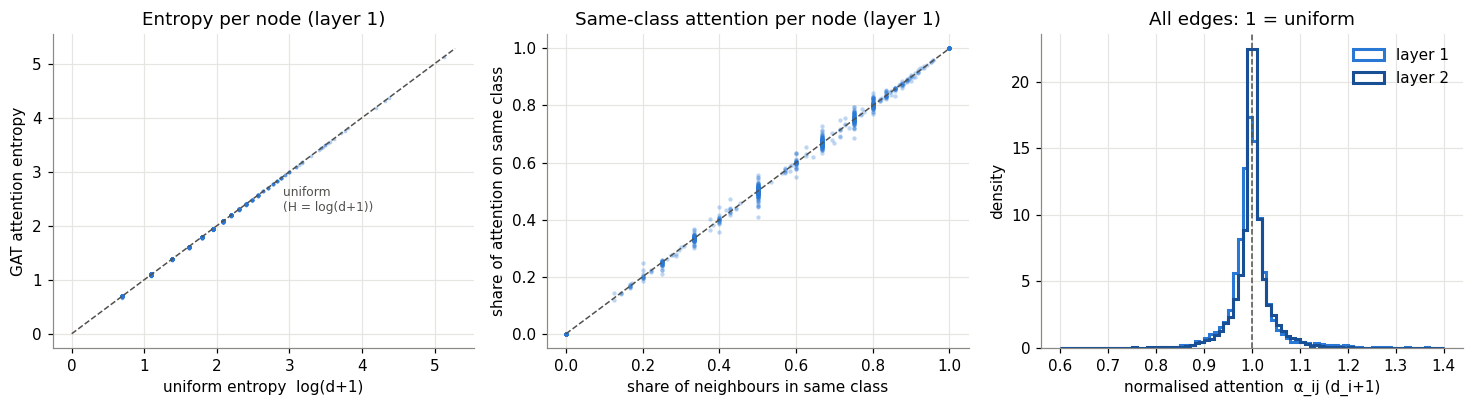

In [12]:
ds = "Cora"; data = datasets[ds]
(ei1, a1), (ei2, a2) = get_attention(gats[ds], data)
st = node_attention_stats(ei1, a1, data.y, data.num_nodes)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))

ax = axes[0]
ax.scatter(st.uniform_entropy, st.entropy, s=6, color=COL["GAT"], alpha=.35, linewidths=0)
lim = [0, st.uniform_entropy.max() * 1.03]; ax.plot(lim, lim, "--", color="#52514e", lw=1)
ax.text(lim[1] * .55, lim[1] * .43, "uniform\n(H = log(d+1))", color="#52514e", fontsize=8)
ax.set_xlabel("uniform entropy  log(d+1)"); ax.set_ylabel("GAT attention entropy"); ax.set_title("Entropy per node (layer 1)")

ax = axes[1]
s = st[st.degree >= 2]
ax.scatter(s.same_class_frac, s.same_class_att, s=8, color=COL["GAT"], alpha=.3, linewidths=0)
ax.plot([0, 1], [0, 1], "--", color="#52514e", lw=1)
ax.set_xlabel("share of neighbours in same class"); ax.set_ylabel("share of attention on same class")
ax.set_title("Same-class attention per node (layer 1)")

ax = axes[2]
for L, (e_, a_), c in [(1, (ei1, a1), COL["GAT"]), (2, (ei2, a2), "#184f95")]:
    nrm = normalized_edge_attention(e_, a_, data.num_nodes)[e_[0] != e_[1]].numpy()
    ax.hist(nrm, bins=np.linspace(.6, 1.4, 81), histtype="step", lw=2, color=c, label=f"layer {L}", density=True)
ax.axvline(1, color="#52514e", ls="--", lw=1); ax.legend()
ax.set_xlabel("normalised attention  α_ij (d_i+1)"); ax.set_ylabel("density"); ax.set_title("All edges: 1 = uniform")
plt.tight_layout(); plt.show()

Every point sits on the diagonal. Each node's attention entropy is essentially the uniform value, and the share of
attention on same-class neighbours equals the share of same-class neighbours. The middle panel is the clearest view:
**GAT does not shift attention towards same-class neighbours**. On Cora 95 % of all edge weights are within about ±7 % of
uniform. CiteSeer is even flatter (table above).

**Is this just averaging over heads?** No. Every individual head is just as flat:

In [13]:
rows = []
for dsn, m in gats.items():
    with torch.no_grad():
        _, atts = m(datasets[dsn].x, datasets[dsn].edge_index, return_attention=True)
    for L, (e_, a) in enumerate(atts, 1):
        for h in range(a.size(1)):
            sh = node_attention_stats(e_, a[:, h], datasets[dsn].y, datasets[dsn].num_nodes); sh = sh[sh.degree >= 2]
            rows.append({"dataset": dsn, "layer": L, "head": h, "entropy / uniform": (sh.entropy / sh.uniform_entropy).mean(),
                         "same-class att − fraction": (sh.same_class_att - sh.same_class_frac).mean()})
heads = pd.DataFrame(rows)
display(heads.groupby(["dataset", "layer"]).agg(heads=("head", "count"),
        min_entropy_ratio=("entropy / uniform", "min"), max_abs_same_class_gain=("same-class att − fraction", lambda s: s.abs().max())).round(4))

heads  min_entropy_ratio  max_abs_same_class_gain
dataset  layer                                                   
CiteSeer 1          8             0.9998                   0.0004
         2          1             0.9985                   0.0003
Cora     1          8             0.9969                   0.0011
         2          1             0.9996                   0.0001

**Why so flat? Look at the raw scores.** Because attention is static (Section 2.3), node $i$'s weights depend only on how much
the neighbour scores $s_j=\mathbf a_{src}^\top W h_j$ vary across its neighbours. If those scores vary by much less than 1,
$\exp(\cdot)$ hardly changes and the softmax is close to uniform.

In [14]:
rows = []
for dsn, m in gats.items():
    x_ = datasets[dsn].x; e_ = datasets[dsn].edge_index
    with torch.no_grad():
        h = m.conv1.W(x_).view(x_.size(0), m.conv1.heads, -1)
        s_src = (h * m.conv1.att_src).sum(-1)                         # [N, heads]
        # spread of neighbour scores within each neighbourhood
        dst = e_[1]; sc = s_src[e_[0]]
        cnt = torch.bincount(dst, minlength=x_.size(0)).float().clamp_min(1).unsqueeze(-1)
        mu = torch.zeros_like(s_src).index_add(0, dst, sc) / cnt
        var = torch.zeros_like(s_src).index_add(0, dst, (sc - mu[dst]) ** 2) / cnt
    rows.append({"dataset": dsn, "std of s_j over all nodes": s_src.std(0).mean().item(),
                 "mean within-neighbourhood std of s_j": var.sqrt().mean().item()})
display(pd.DataFrame(rows).set_index("dataset").round(4))

,std of s_j over all nodes,mean within-neighbourhood std of s_j
dataset,,
Cora,0.1355,0.0573
CiteSeer,0.0366,0.0094


Within a neighbourhood the neighbour scores differ by only ~0.06 (Cora) and ~0.01 (CiteSeer), so
$\exp(s_j)$ changes by at most a few percent and the softmax returns near-uniform weights. Several things plausibly push
in this direction: the inputs are sparse, row-normalised bag-of-words vectors; weight decay penalises the attention
vector $\mathbf a$ like any other weight; dropout of 0.6 is also applied to the attention weights, which makes it risky
to rely on any single neighbour; and only 140 labels are available. Uniform
attention already fits this graph well (81 % of Cora's edges are same-class). Static attention gives little reason to
leave that point.

### Neighbourhoods drawn with attention
The figure shows a few nodes with large, mixed neighbourhoods. Edge width is proportional to normalised attention
(layer 2, the layer that produces the prediction). Blue neighbours share the centre's class; orange ones do not.

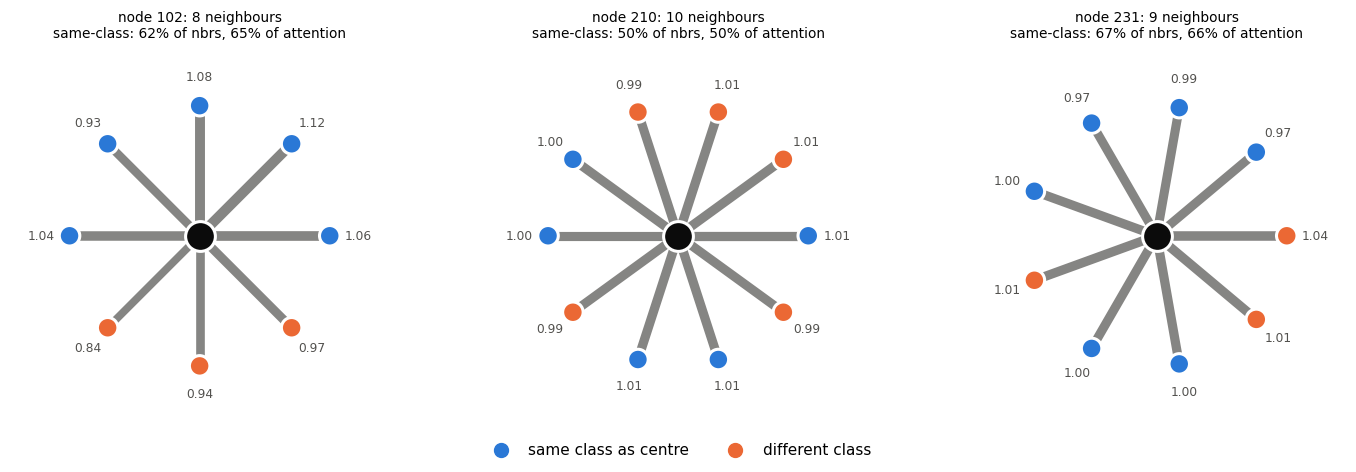

In [15]:
st2 = node_attention_stats(ei2, a2, data.y, data.num_nodes)
cand = st2[(st2.degree >= 8) & (st2.degree <= 14) & (st2.same_class_frac.between(.3, .7))].index[:3].tolist()
fig, axes = plt.subplots(1, len(cand), figsize=(4.4 * len(cand), 4.2))
for ax, c in zip(np.atleast_1d(axes), cand):
    m_ = (ei2[1] == c) & (ei2[0] != c)
    nb, w = ei2[0][m_].tolist(), normalized_edge_attention(ei2, a2, data.num_nodes)[m_].tolist()
    g = nx.star_graph(len(nb)); p = nx.circular_layout(nx.Graph([(k, k) for k in range(1, len(nb) + 1)]))
    p[0] = np.zeros(2)
    for k, (j, wj) in enumerate(zip(nb, w), 1):
        ax.plot([0, p[k][0]], [0, p[k][1]], color="#52514e", lw=6 * wj, alpha=.7, solid_capstyle="round")
        ax.text(*(p[k] * 1.22), f"{wj:.2f}", ha="center", va="center", fontsize=8, color="#52514e")
    colors = [SAME if data.y[j] == data.y[c] else OTHER for j in nb]
    ax.scatter([p[k][0] for k in range(1, len(nb) + 1)], [p[k][1] for k in range(1, len(nb) + 1)], s=180, c=colors,
               edgecolors="white", linewidths=2, zorder=3)
    ax.scatter([0], [0], s=380, c="#0b0b0b", edgecolors="white", linewidths=2, zorder=3)
    sc_ = st2.loc[c]
    ax.set_title(f"node {c}: {int(sc_.degree)} neighbours\nsame-class: {sc_.same_class_frac:.0%} of nbrs, {sc_.same_class_att:.0%} of attention",
                 fontsize=9)
    ax.set_xlim(-1.45, 1.45); ax.set_ylim(-1.45, 1.45); ax.set_aspect("equal"); ax.axis("off")
from matplotlib.lines import Line2D
fig.legend([Line2D([], [], marker="o", ls="", color=SAME, ms=9), Line2D([], [], marker="o", ls="", color=OTHER, ms=9)],
           ["same class as centre", "different class"], loc="lower center", ncol=2)
plt.tight_layout(rect=(0, .06, 1, 1)); plt.show()

### Learned embeddings (t-SNE)
If GAT behaves like averaging, its hidden representations should look much like GCN's. We train a GCN with the same seed
and project both 64-d (GAT) / 16-d (GCN) hidden layers with t-SNE. The **silhouette score** (computed on the hidden
vectors with true labels; higher means better-separated classes) puts a number on the comparison.

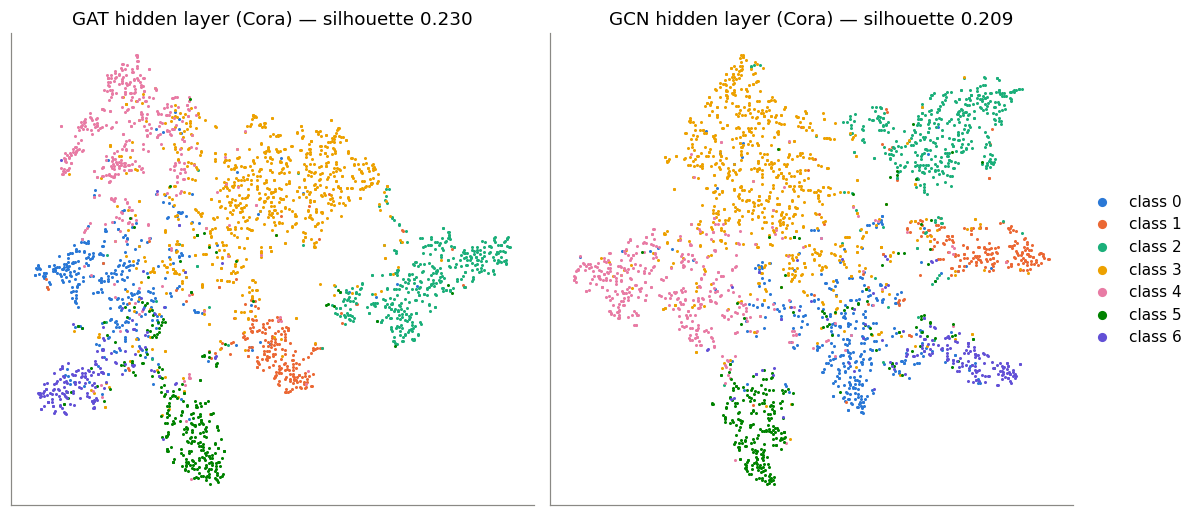

In [16]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
gcn, gcn_m = train_model("GCN", data, seed=0, device=torch.device("cpu"))
CLASS_COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, mdl) in zip(axes, [("GAT", gats["Cora"]), ("GCN", gcn)]):
    with torch.no_grad():
        z = mdl.embed(data.x, data.edge_index).numpy()
    sil = silhouette_score(z, data.y.numpy())
    xy = TSNE(2, random_state=0, init="pca", perplexity=30).fit_transform(z)
    for k in range(7):
        mk = data.y.numpy() == k
        ax.scatter(xy[mk, 0], xy[mk, 1], s=4, color=CLASS_COL[k], label=f"class {k}", linewidths=0)
    ax.set_title(f"{name} hidden layer (Cora), silhouette {sil:.3f}"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[1].legend(markerscale=3, loc="center left", bbox_to_anchor=(1, .5))
plt.tight_layout(); plt.show()

**Answer to RQ2: the attention is close to uniform.** It is not concentrated on same-class neighbours beyond what
the graph's homophily already gives. GAT's embeddings show class structure similar to GCN's (silhouette 0.23 vs 0.21; the hidden sizes differ, 64 vs 16). The trained GAT
works as a well-regularised neighbourhood average, which explains why its accuracy matches GCN's (E1).

## 7. E3: Noisy neighbours (RQ3)
We add random undirected edges equal to 0, 10, 25, 50 and 100 % of Cora's 5,278 edges. Pairs are drawn uniformly, so
with 7 classes ~82 % of the injected edges join different classes. Each seed uses its own noisy graph, shared by all
models (paired). If attention lets GAT ignore bad neighbours, its curve should fall more slowly, and injected edges
should get normalised attention well below 1.

In [17]:
e3 = pd.read_csv(f"{RES}/e3_noise.csv")
print("share of injected edges that are cross-class:", e3.injected_cross_class.dropna().mean().round(3))
models3 = [m for m in ["GAT", "GCN", "SAGE", "MLP", "GATv2"] if m in e3.model.unique()]
acc = e3.groupby(["model", "noise"]).test_acc.agg(["mean", "std"]) * 100
display(acc["mean"].unstack(0)[models3].round(1).rename_axis("noise ratio").style.format("{:.1f}").set_caption("mean test accuracy (%), 10 seeds"))

share of injected edges that are cross-class: 0.821


model,GAT,GCN,SAGE,MLP,GATv2
noise ratio,,,,,
0.000000,82.3,82.1,81.3,59.0,82.2
0.100000,80.4,80.0,79.6,59.0,79.7
0.250000,77.4,77.9,77.4,59.0,77.2
0.500000,73.0,73.9,74.2,59.0,72.6
1.000000,69.0,68.2,71.6,59.0,67.2


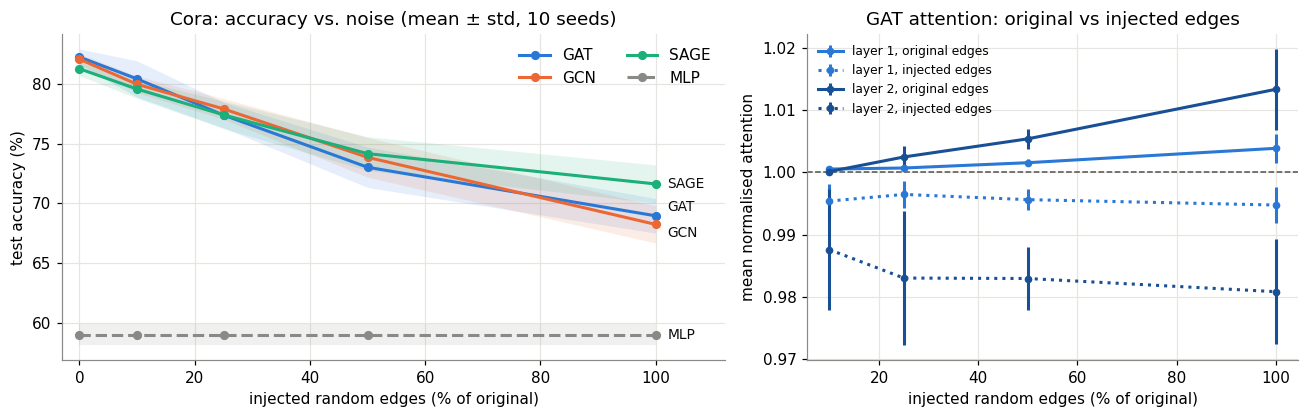

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
for m in [m for m in ["GAT", "GCN", "SAGE", "MLP"] if m in models3]:
    a = acc.loc[m]; xs = 100 * a.index.values
    ax.plot(xs, a["mean"], marker="o", ms=5, color=COL[m], ls="--" if m == "MLP" else "-", label=m)
    ax.fill_between(xs, a["mean"] - a["std"], a["mean"] + a["std"], color=COL[m], alpha=.12, linewidth=0)
    nudge = {"GAT": .7, "GCN": -.7}.get(m, 0)
    ax.text(xs[-1] + 2, a["mean"].iloc[-1] + nudge, m, color="#0b0b0b", va="center", fontsize=9)
ax.set_xlabel("injected random edges (% of original)"); ax.set_ylabel("test accuracy (%)")
ax.set_title("Cora: accuracy vs. noise (mean ± std, 10 seeds)"); ax.set_xlim(-3, 112); ax.legend(loc="upper right", ncol=2)

ax = axes[1]
g = e3[(e3.model == "GAT") & (e3.noise > 0)].groupby("noise")
for L, c in [(1, COL["GAT"]), (2, "#184f95")]:
    for kind, ls in [("original", "-"), ("injected", ":")]:
        col = f"L{L}_att_{kind}"
        ax.errorbar(100 * g[col].mean().index, g[col].mean(), yerr=g[col].std(), color=c, ls=ls, marker="o", ms=4,
                    capsize=0, label=f"layer {L}, {kind} edges")
ax.axhline(1, color="#52514e", lw=1, ls="--")
ax.set_xlabel("injected random edges (% of original)"); ax.set_ylabel("mean normalised attention")
ax.set_title("GAT attention: original vs injected edges"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
rows = []
p = e3.pivot_table(index=["noise", "seed"], columns="model", values="test_acc") * 100
base = p.xs(0.0, level="noise")
for m in ["GAT", "GCN", "SAGE"]:
    drop = (base[m] - p.xs(1.0, level="noise")[m])
    rows.append({"model": m, "acc @0%": base[m].mean(), "acc @100%": p.xs(1.0, level="noise")[m].mean(), "drop (pts)": drop.mean(), "drop std": drop.std()})
display(pd.DataFrame(rows).set_index("model").round(2))
d = p.xs(1.0, level="noise")
print(f"at 100% noise: GAT − GCN = {(d.GAT - d.GCN).mean():+.2f} pts (p={stats.ttest_rel(d.GAT, d.GCN).pvalue:.3f}); "
      f"SAGE − GAT = {(d.SAGE - d.GAT).mean():+.2f} pts (p={stats.ttest_rel(d.SAGE, d.GAT).pvalue:.4f})")

,acc @0%,acc @100%,drop (pts),drop std
model,,,,
GAT,82.26,68.96,13.30,1.71
GCN,82.08,68.24,13.84,1.57
SAGE,81.28,71.63,9.65,1.82


at 100% noise: GAT − GCN = +0.72 pts (p=0.210); SAGE − GAT = +2.67 pts (p=0.0013)


**Answer to RQ3: no.**
* GAT loses ~13 points going from 0 % to 100 % noise, about the same as GCN. GraphSAGE degrades least and is ~2.6 points
  ahead of GAT at 100 % noise. GraphSAGE has a **separate weight for the node's own features** ($W_1h_i+W_2\,\mathrm{mean}_j h_j$),
  so it can learn to trust itself more as neighbourhoods get noisier. GAT and GCN only ever mix self and neighbours with
  one shared $W$.
* GAT does notice the injected edges, but only faintly. In layer 2 they receive ~0.98× the uniform weight vs ~1.01× for
  real edges, and layer 1 hardly separates them at all. A 2–3 % difference in weight cannot cancel neighbourhoods where up
  to half the edges are noise.
* All graph models stay above the MLP (59 %) even at 100 % noise, because the original edges still carry signal.

## 8. Stretch: GATv2 and low-homophily graphs
Two follow-ups to the finding that attention ≈ averaging:
1. **GATv2** (dynamic attention, Section 2.3) on Cora/CiteSeer and on the noisy graphs. Does a more expressive scorer lead to
   attention that is less uniform, and to better accuracy or robustness?
2. **Low-homophily graphs:** Texas (WebKB, 183 nodes, homophily ≈ 0.1) and Chameleon (Wikipedia, 2,277 nodes,
   homophily ≈ 0.23). Here most neighbours have a different class (on Texas, a student's page links mostly to course and faculty pages,
   not to other students' pages), so uniform averaging should hurt, which gives
   attention a reason to be selective. These use the 10 standard Geom-GCN splits (split k for seed k).

In [20]:
STRETCH_DS = ["Texas", "Chameleon"]
if RUN_EXPERIMENTS:
    !python scripts/run_experiments.py --exp e1 --models GATv2 --datasets Cora CiteSeer
    !python scripts/run_experiments.py --exp e3 --models GATv2
    !python scripts/run_experiments.py --exp e1 --models MLP GCN SAGE GAT GATv2 --datasets Texas Chameleon
e1 = pd.read_csv(f"{RES}/e1_benchmark.csv")
hom = {ds: edge_homophily(load_dataset(ds, DATA)[1].edge_index, load_dataset(ds, DATA)[1].y) for ds in ["Cora", "CiteSeer"] + STRETCH_DS}
order = ["MLP", "GCN", "SAGE", "GAT", "GATv2"]
t = e1.groupby(["dataset", "model"]).test_acc.agg(lambda s: f"{100*s.mean():.1f} ± {100*s.std():.1f}").unstack()
t = t.reindex(index=[d for d in ["Cora", "CiteSeer"] + STRETCH_DS if d in t.index], columns=[m for m in order if m in t.columns])
t.insert(0, "edge homophily", [round(hom[d], 2) for d in t.index])
display(t)

model,edge homophily,MLP,GCN,SAGE,GAT,GATv2
dataset,,,,,,
Cora,0.81,59.0 ± 0.9,82.1 ± 0.5,81.3 ± 0.6,82.3 ± 0.7,82.3 ± 0.9
CiteSeer,0.74,57.3 ± 1.1,71.0 ± 0.4,70.2 ± 0.7,71.5 ± 0.9,72.0 ± 1.3
Texas,0.06,80.3 ± 5.6,62.2 ± 4.0,84.3 ± 5.9,58.4 ± 4.1,59.2 ± 5.5
Chameleon,0.23,47.4 ± 1.6,55.5 ± 1.5,61.9 ± 1.9,57.4 ± 2.0,58.1 ± 2.5


**GATv2 vs GAT** (paired over the same 10 seeds / splits):

In [21]:
rows = []
for dsn in t.index:
    p = e1[e1.dataset == dsn].pivot(index="seed", columns="model", values="test_acc") * 100
    d = p.GATv2 - p.GAT
    rows.append({"dataset": dsn, "edge homophily": round(hom[dsn], 2), "GATv2 − GAT (pts)": d.mean(),
                 "paired t p-value": stats.ttest_rel(p.GATv2, p.GAT).pvalue, "GATv2 wins": f"{(d > 0).sum()}/10",
                 "best model": p.mean().idxmax()})
display(pd.DataFrame(rows).set_index("dataset").round(3))

,edge homophily,GATv2 − GAT (pts),paired t p-value,GATv2 wins,best model
dataset,,,,,
Cora,0.81,0.050,0.874,6/10,GATv2
CiteSeer,0.74,0.490,0.294,7/10,GATv2
Texas,0.06,0.811,0.279,5/10,SAGE
Chameleon,0.23,0.724,0.263,6/10,SAGE


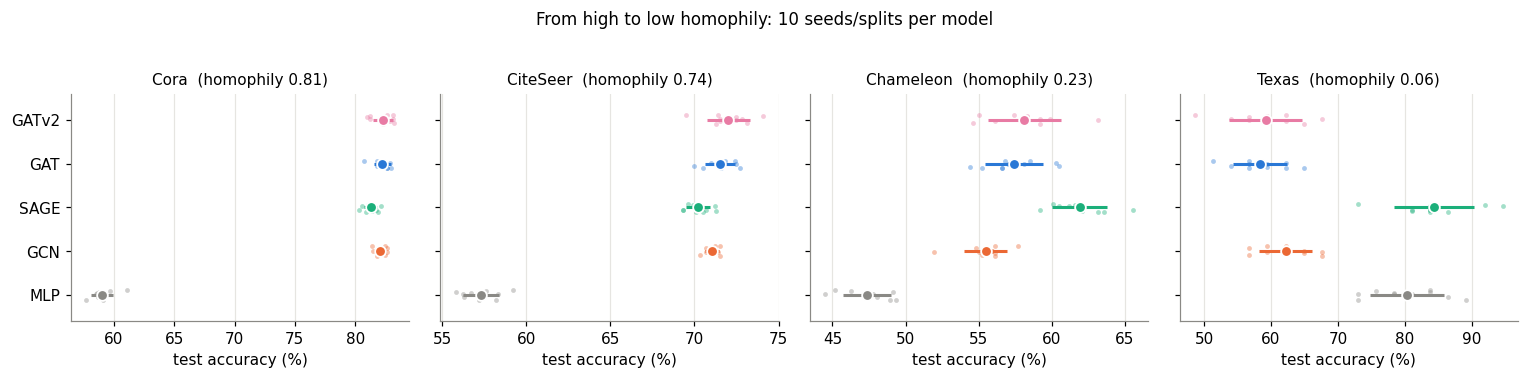

In [22]:
order_ds = sorted(t.index, key=lambda d: -hom[d])
fig, axes = plt.subplots(1, len(order_ds), figsize=(14, 3.3), sharey=True)
for ax, dsn in zip(axes, order_ds):
    d = e1[e1.dataset == dsn]
    for k, m in enumerate(order):
        acc = 100 * d[d.model == m].test_acc.values
        ax.scatter(acc, k + np.random.default_rng(k).uniform(-.12, .12, len(acc)), s=10, color=COL[m], alpha=.4, linewidths=0)
        ax.errorbar(acc.mean(), k, xerr=acc.std(ddof=1), fmt="o", ms=7, color=COL[m], elinewidth=2,
                    markeredgecolor="white", markeredgewidth=1.2)
    ax.set_title(f"{dsn}  (homophily {hom[dsn]:.2f})", fontsize=10); ax.set_xlabel("test accuracy (%)"); ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(order)), order); axes[0].set_ylim(-.6, len(order) - .4)
plt.suptitle("From high to low homophily: 10 seeds/splits per model", y=1.03, fontsize=11)
plt.tight_layout(); plt.show()

**Does attention become selective when it is needed?** We repeat the E2 analysis for GAT and GATv2 (seed 0) on all four
graphs. On Texas and Chameleon most neighbours belong to a different class, so a model that could tell them apart
should shift attention towards the few same-class neighbours.

In [23]:
rows = []
for dsn in order_ds:
    dd = datasets[dsn] if dsn in datasets else select_split(load_dataset(dsn, DATA)[1], 0)
    for name in ["GAT", "GATv2"]:
        mdl = build_model(name, dd.num_features, int(dd.y.max()) + 1)
        mdl.load_state_dict(torch.load(f"{RES}/{name}_{dsn}_seed0.pt", map_location="cpu"))
        rows += [{"dataset": dsn, **r} for r in attention_summary(mdl, dd, name)]
att_all = pd.DataFrame(rows).set_index(["dataset", "model", "layer"])
display(att_all[["entropy / uniform", "same-class attention", "same-class fraction (uniform)", "norm. att. 5–95% range"]].round(3))

entropy / uniform  same-class attention  \
dataset   model layer                                            
Cora      GAT   1                  0.999                 0.816   
                2                  1.000                 0.816   
          GATv2 1                  1.000                 0.816   
                2                  1.000                 0.816   
CiteSeer  GAT   1                  1.000                 0.720   
                2                  0.999                 0.720   
          GATv2 1                  1.000                 0.720   
                2                  0.999                 0.721   
Chameleon GAT   1                  0.995                 0.254   
                2                  0.969                 0.247   
          GATv2 1                  0.996                 0.253   
                2                  0.969                 0.250   
Texas     GAT   1                  1.000                 0.066   
                2                  0.984                 0.062   
          GATv2 1                  1.000                 0.065   
                2                  0.996                 0.063   

                       same-class fraction (uniform) norm. att. 5–95% range  
dataset   model layer                                                        
Cora      GAT   1                              0.816              0.93–1.07  
                2                              0.816              0.94–1.06  
          GATv2 1                              0.816              0.99–1.01  
                2                              0.816              0.93–1.07  
CiteSeer  GAT   1                              0.720              0.99–1.01  
                2                              0.720              0.89–1.11  
          GATv2 1                              0.720              0.99–1.01  
                2                              0.720              0.90–1.11  
Chameleon GAT   1                              0.251              0.78–1.25  
                2                              0.251              0.64–1.32  
          GATv2 1                              0.251              0.81–1.26  
                2                              0.251              0.45–1.45  
Texas     GAT   1                              0.065              0.98–1.02  
                2                              0.065              0.64–1.44  
          GATv2 1                              0.065              0.98–1.02  
                2                              0.065              0.82–1.22

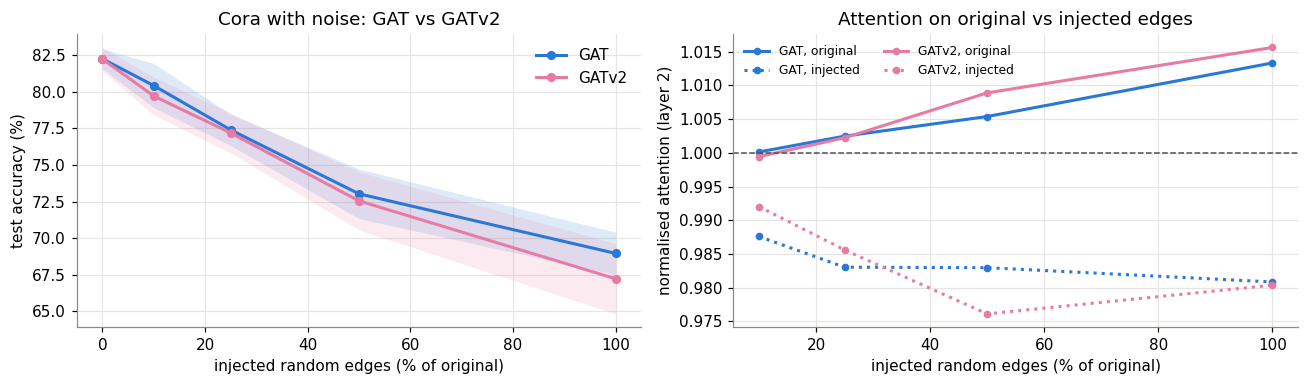

In [24]:
e3v = e3[e3.model.isin(["GAT", "GATv2"])]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for m in ["GAT", "GATv2"]:
    a = e3v[e3v.model == m].groupby("noise").test_acc.agg(["mean", "std"]) * 100; xs = 100 * a.index.values
    ax.plot(xs, a["mean"], marker="o", ms=5, color=COL[m], label=m)
    ax.fill_between(xs, a["mean"] - a["std"], a["mean"] + a["std"], color=COL[m], alpha=.15, linewidth=0)
ax.set_xlabel("injected random edges (% of original)"); ax.set_ylabel("test accuracy (%)"); ax.legend()
ax.set_title("Cora with noise: GAT vs GATv2")
ax = axes[1]
for m in ["GAT", "GATv2"]:
    g = e3v[(e3v.model == m) & (e3v.noise > 0)].groupby("noise")
    for kind, ls in [("original", "-"), ("injected", ":")]:
        ax.plot(100 * g[f"L2_att_{kind}"].mean().index, g[f"L2_att_{kind}"].mean(), ls=ls, marker="o", ms=4,
                color=COL[m], label=f"{m}, {kind}")
ax.axhline(1, color="#52514e", lw=1, ls="--"); ax.legend(fontsize=8, ncol=2)
ax.set_xlabel("injected random edges (% of original)"); ax.set_ylabel("normalised attention (layer 2)")
ax.set_title("Attention on original vs injected edges")
plt.tight_layout(); plt.show()

**What the stretch experiments show**
* **GATv2 ≈ GAT everywhere.** The difference is +0.05 to +0.8 points on all four graphs, with no case significant
  ($p>0.26$). On noisy Cora GATv2 is no more robust (67.2 % vs 69.0 % at 100 % noise). It gives injected edges about
  the same ~2 % discount in layer 2 as GAT.
* **Attention stays class-blind, even where it should not.** On Texas only 6.5 % of neighbours share the node's class.
  A selective model would raise that share, but GAT and GATv2 put 6.2–6.5 % of their attention there, which is the
  uniform value. On Chameleon the weights spread out more (5–95 % range up to 0.45–1.45 × uniform), but the spread is
  not aligned with class (same-class attention 0.25 vs fraction 0.25). The extra expressiveness of dynamic attention
  is available, but training does not use it to find same-class neighbours.
* **On heterophilous graphs, separating self from neighbours matters most.** On Texas the graph-free MLP (80.3 %)
  beats GCN, GAT and GATv2 (58–62 %) by about 20 points: mixing in mostly wrong-class neighbours hurts. GraphSAGE
  (84.3 %) keeps a separate weight for the node's own features and is the best model. On Chameleon GraphSAGE is also
  best (61.9 % vs 57–58 % for the attention models).

This supports the explanation from E2/E3. In these settings the bottleneck is not which neighbours to weight. It is
**how much to trust the neighbourhood at all**, and attention as used in GAT/GATv2 does not learn to answer that from the
few labels available.

## 9. Conclusions
| Question | Answer |
|---|---|
| **RQ1** Does GAT beat GCN / GraphSAGE by more than seed noise? | Not GCN (+0.2 / +0.5 pts, $p>0.2$). Yes GraphSAGE-mean (+1.0 / +1.3 pts, $p<0.01$). |
| **RQ2** Is attention uniform or same-class focused? | **Uniform.** Entropy ≈ 99.9 % of uniform; same-class attention = same-class fraction, in every head. |
| **RQ3** Does GAT resist noisy edges? | **No.** It degrades like GCN, and injected edges get only ~2 % less attention. GraphSAGE's separate self-weight helps more. |
| **Stretch** GATv2 / low homophily | GATv2 ≈ GAT (no significant difference on 4 graphs); attention stays class-blind even on Texas/Chameleon, where GraphSAGE wins. |

**Takeaways**
* On homophilous citation graphs, which neighbours to trust is not the bottleneck. Averaging is already a good rule,
  and a regularised GAT learns to (nearly) average.
* GAT's attention is **static**: it ranks neighbours the same way for every query node (Section 2.3). Making it dynamic (GATv2)
  did not help here, so the limit in practice is what training learns from few labels, not only expressiveness.
* Attention weights are only worth interpreting when they **differ from the uniform baseline**. Always plot them against
  $1/(d_i+1)$ and against the homophily level, never on their own.
* Architecture details beyond attention, like a separate self-connection, mattered more for robustness than attention did.

**Limitations**
* Only the standard public splits, one hyperparameter setting per model (taken from the papers), and no tuning. With
  tuning, rankings can change by about a point.
* E2 analyses one trained model per dataset (seed 0). E3's attention numbers average over all 10 seeds.
* GPU runs are not bit-for-bit deterministic (see Section 4), so a rerun can move individual results slightly; means changed by ≤ 0.5 points.
* Random-edge noise is one kind of corruption. Adversarial or feature noise could behave differently.

## 10. Contributions, use of AI, and resources
**Team contributions.** Individual project: Hansi Yasodara did the background reading, experiment design, code,
experiments, analysis and the write-up.

**How AI was used.** I used Claude Code (Anthropic) as a coding assistant to help scaffold the code (`src/`, `scripts/`,
tests), debug the experiment pipeline, and draft parts of this notebook's text and figures. All design decisions follow
my proposal. I reviewed, ran and checked the code. The from-scratch GAT layer is verified numerically against PyG's
`GATConv` (Section 3), and every number in the text comes from the result files in `results/`.

**Resources and existing code.**
* PyTorch and **PyTorch Geometric** (Fey & Lenssen, 2019): datasets, `GCNConv`, `SAGEConv`, `GATv2Conv`, and `GATConv`
  (used only as a reference for checking our layer).
* Hyperparameters from the GCN and GAT papers. Google Colab (T4 GPU) for all experiments.

**References**
1. P. Veličković et al. "Graph Attention Networks." ICLR 2018. arXiv:1710.10903
2. T. Kipf & M. Welling. "Semi-Supervised Classification with Graph Convolutional Networks." ICLR 2017. arXiv:1609.02907
3. W. Hamilton, R. Ying & J. Leskovec. "Inductive Representation Learning on Large Graphs." NeurIPS 2017. arXiv:1706.02216
4. S. Brody, U. Alon & E. Yahav. "How Attentive are Graph Attention Networks?" ICLR 2022. arXiv:2105.14491
5. M. Fey & J. E. Lenssen. "Fast Graph Representation Learning with PyTorch Geometric." 2019. arXiv:1903.02428
6. O. Shchur et al. "Pitfalls of Graph Neural Network Evaluation." 2018. arXiv:1811.05868
7. H. Pei et al. "Geom-GCN: Geometric Graph Convolutional Networks." ICLR 2020. arXiv:2002.05287 (Texas / Chameleon splits)